## Analiza rzeczywistych danych medycznych 3D (TK / DICOM) — MPR, MIP / MinIP oraz Wolumetria

Ten notatnik stanowi adaptację potoku analizy obrazów medycznych 3D na potrzeby **pełnowymiarowego badania tomografii komputerowej (TK / CT) w formacie DICOM** (paczka **150 przekrojów osiowych** spakowana w archiwum `.zip`).

### Wprowadzenie i specyfika danych TK (DICOM) względem MRI
W przeciwieństwie do uproszczonego wolumenu MRI z biblioteki `scikit-image` (10 warstw o dowolnej skali jasności), rzeczywista seria **150 plików DICOM z tomografu komputerowego** posiada kluczowe właściwości fizyczne i geometryczne:
1. **Automatyczne metadane przestrzenne DICOM:** `SimpleITK` odczytuje bezpośrednio z nagłówków plików `.dcm` rzeczywisty rozmiar piksela (`PixelSpacing`), położenie warstw (`ImagePositionPatient` $\rightarrow$ `Spacing` i `Origin`) oraz macierz orientacji pacjenta (`Direction`), sortując przekroje według współrzędnej przestrzennej $Z$, a nie alfabetycznie po nazwach plików.
2. **Skala jednostek Hounsfielda (HU):** Intensywności wokseli są skalibrowane fizycznie (automatycznie przeliczane przez `SimpleITK` z użyciem tagów `RescaleSlope` i `RescaleIntercept`): powietrze $\approx -1000\;\text{HU}$, tkanka tłuszczowa $\approx -100\text{ do }-50\;\text{HU}$, woda $= 0\;\text{HU}$, tkanki miękkie $\approx +20\text{ do }+80\;\text{HU}$, kości / zwapnienia / kontrast $> +250\;\text{HU}$.
3. **Okienkowanie TK (*CT Windowing*):** Ponieważ badanie TK obejmuje szeroki zakres około $4000\;\text{HU}$, poprawna wizualizacja wymaga zastosowania odpowiedniego okna diagnostycznego (*Window Level* `WL` oraz *Window Width* `WW`), np. okna tkanek miękkich, płucnego lub kostnego.

In [2]:
# Instalacja i import niezbędnych bibliotek
#!pip install -q SimpleITK pydicom scipy pandas matplotlib

import os
import shutil
import zipfile
import SimpleITK as sitk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import binary_fill_holes, binary_opening

print(f"Środowisko 3D TK/DICOM gotowe (SimpleITK {sitk.__version__})")

Środowisko 3D TK/DICOM gotowe (SimpleITK 2.5.7)


---
## Krok 1: Rozpakowanie archiwum ZIP i wczytanie wolumenu TK 3D z plików DICOM

W tym kroku:
1. Rozpakowujemy archiwum `.zip` zawierające **150 obrazów DICOM** do folderu roboczego.
2. Przeszukujemy katalog (wraz z ewentualnymi podfolderami) za pomocą `sitk.ImageSeriesReader().GetGDCMSeriesIDs()`, aby zidentyfikować serię DICOM i ułożyć pliki w poprawnej kolejności anatomicznej wzdłuż osi $Z$.
3. Odczytujemy metadane badania z nagłówków DICOM (`Modality`, `PixelSpacing`, `SliceThickness`, `Origin`) oraz wyświetlamy surowy przekrój osiowy (*Axial*) i czołowy (*Coronal*) przed resamplingiem.

Znaleziono archiwum ZIP: ct-lung-screening-nlst-series.zip
ID serii DICOM                        : 1.2.840.113654.2.55.57669092321627294898588883865157458147
Liczba wczytanych warstw DICOM        : 150 obrazów
Modalność / Opis serii                : CT | NLST-LSS (0,OPA,SE,VZOOM,B30f,278,2,120,60,30,na)
Rozmiar wolumenu 3D (X, Y, Z)         : (512, 512, 150) wokseli
Rozmiar woksela Spacing (mm)          : (0.543, 0.543, 2.0) (SliceThickness=2 mm)
Punkt początkowy Origin (mm)          : (-138.73, -260.73, -549.4)
Zakres gęstości radiologicznej [HU]   : [-1024, 2011] HU


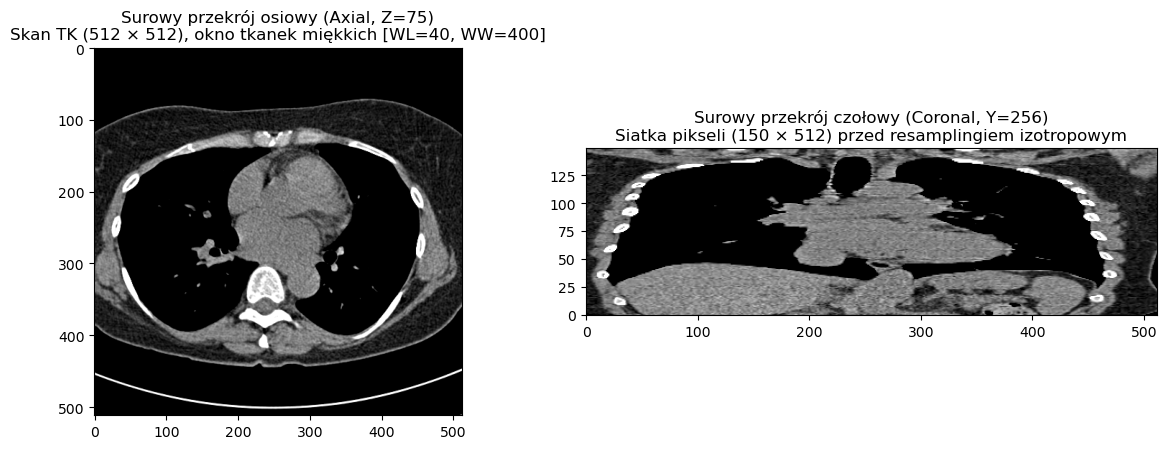

In [5]:
# 1. Ścieżka do archiwum ZIP z wynikami TK (zmień nazwę pliku, jeśli jest inna)
ZIP_PATH = "wyniki_tk.zip"
EXTRACT_DIR = "dane_tk_dicom"

# Automatyczne wyszukanie pliku .zip w bieżącym katalogu, jeśli domyślny nie istnieje
if not os.path.exists(ZIP_PATH):
    zip_candidates = [f for f in os.listdir(".") if f.lower().endswith(".zip")]
    if zip_candidates:
        ZIP_PATH = zip_candidates[0]
        print(f"Znaleziono archiwum ZIP: {ZIP_PATH}")

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        f"Nie znaleziono pliku '{ZIP_PATH}'. Wgraj archiwum ZIP do katalogu roboczego lub podaj poprawną ścieżkę w zmiennej ZIP_PATH."
    )

# Wyczyszczenie i rozpakowanie archiwum ZIP
if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

# 2. Wyszukanie serii DICOM (również w podkatalogach archiwum) i posortowanie warstw przestrzennie
reader = sitk.ImageSeriesReader()
best_series_files = []
best_series_id = None

for root, _, _ in os.walk(EXTRACT_DIR):
    if "__MACOSX" in root:
        continue
    series_ids = reader.GetGDCMSeriesIDs(root)
    for sid in series_ids:
        files = reader.GetGDCMSeriesFileNames(root, sid)
        if len(files) > len(best_series_files):
            best_series_files = files
            best_series_id = sid

if not best_series_files:
    raise RuntimeError("W rozpakowanym archiwum ZIP nie znaleziono poprawnej serii plików DICOM!")

reader.SetFileNames(best_series_files)
reader.MetaDataDictionaryArrayUpdateOn()
reader.LoadPrivateTagsOn()

# Wczytanie wolumenu 3D i konwersja do float32 (zachowanie dokładnych wartości HU)
vol_3d_raw = reader.Execute()
vol_3d = sitk.Cast(vol_3d_raw, sitk.sitkFloat32)
ct_arr = sitk.GetArrayFromImage(vol_3d)  # kształt (Z, Y, X)

# Odczyt wybranych tagów DICOM z pierwszej warstwy
def get_dicom_tag(rdr, tag, default="Brak danych"):
    return rdr.GetMetaData(0, tag).strip() if rdr.HasMetaDataKey(0, tag) else default

modality = get_dicom_tag(reader, "0008|0060")
study_desc = get_dicom_tag(reader, "0008|1030")
series_desc = get_dicom_tag(reader, "0008|103e")
slice_thickness = get_dicom_tag(reader, "0018|0050")

print(f"ID serii DICOM                        : {best_series_id}")
print(f"Liczba wczytanych warstw DICOM        : {len(best_series_files)} obrazów")
print(f"Modalność / Opis serii                : {modality} | {study_desc} ({series_desc})")
print(f"Rozmiar wolumenu 3D (X, Y, Z)         : {vol_3d.GetSize()} wokseli")
print(f"Rozmiar woksela Spacing (mm)          : {tuple(round(s, 3) for s in vol_3d.GetSpacing())} (SliceThickness={slice_thickness} mm)")
print(f"Punkt początkowy Origin (mm)          : {tuple(round(o, 2) for o in vol_3d.GetOrigin())}")
print(f"Zakres gęstości radiologicznej [HU]   : [{ct_arr.min():.0f}, {ct_arr.max():.0f}] HU")

# Funkcja pomocnicza do okienkowania TK (Window Level / Window Width)
def apply_ct_window(slice_2d, wl=40.0, ww=400.0):
    low = wl - ww / 2.0
    high = wl + ww / 2.0
    return np.clip(slice_2d, low, high)

# Podgląd surowego przekroju osiowego (środkowa warstwa Z) oraz surowego przekroju czołowego (Y)
mid_z = ct_arr.shape[0] // 2
mid_y = ct_arr.shape[1] // 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].imshow(apply_ct_window(ct_arr[mid_z, :, :], wl=40, ww=400), cmap="gray")
ax[0].set_title(f"Surowy przekrój osiowy (Axial, Z={mid_z})\nSkan TK ({ct_arr.shape[2]} × {ct_arr.shape[1]}), okno tkanek miękkich [WL=40, WW=400]")
ax[1].imshow(apply_ct_window(ct_arr[:, mid_y, :], wl=40, ww=400), cmap="gray", origin="lower")
ax[1].set_title(f"Surowy przekrój czołowy (Coronal, Y={mid_y})\nSiatka pikseli ({ct_arr.shape[0]} × {ct_arr.shape[2]}) przed resamplingiem izotropowym")
plt.tight_layout()
plt.show()

---
### Krok 2: Implementacja funkcji analizy 3D TK — resampling izotropowy, MPR / MIP / MinIP oraz wolumetria

Poniżej znajduje się pełna implementacja funkcji dostosowanych do tomografii komputerowej w jednostkach Hounsfielda (HU):
1. `resample_to_isotropic()` — resampling trójliniowy (`sitkLinear`) do jednolitej siatki izotropowej $1.0 \times 1.0 \times 1.0\;\text{mm}$ z wypełnieniem tła wartością minimalną wolumenu (powietrze $\approx -1000\;\text{HU}$).
2. `extract_mpr_and_projections()` — wyznaczenie ortogonalnych przekrojów **MPR** (*Axial*, *Coronal*, *Sagittal*) w zadanym punkcie fizycznym `target_mm` (domyślnie środek geometryczny skanu) oraz projekcji grubowarstwowych `Coronal MIP` (`np.max`) i `Coronal MinIP` (`np.min`) z warstwy o grubości `24 mm`.
3. `quantify_structure_3d()` — segmentacja progowa w jednostkach Hounsfielda (`hu_range`) oraz oczyszczanie morfologiczne (`binary_opening` + `binary_fill_holes`) wewnątrz zadanego ROI 3D (lub całego wolumenu) wraz z obliczeniem objętości w $\text{cm}^3$, średniej gęstości w $\text{HU}$ i wymiarów fizycznych w $\text{mm}$.

In [8]:
# ---------------------------------------------------------
# FUNKCJE ANALIZY 3D DLA SKANU TK (HOUNSFIELD UNITS)
# ---------------------------------------------------------

def get_volume_center_mm(image_3d):
    """Zwraca współrzędne fizyczne (x, y, z) w mm środka wolumenu 3D."""
    size = image_3d.GetSize()
    center_idx = (int(size[0] // 2), int(size[1] // 2), int(size[2] // 2))
    return tuple(float(c) for c in image_3d.TransformIndexToPhysicalPoint(center_idx))


def resample_to_isotropic(image_3d, new_spacing=(1.0, 1.0, 1.0)):
    """
    Przeskalowuje wolumen TK 3D SimpleITK do zadanej rozdzielczości izotropowej (w mm).
    Wartość tła poza obszarem skanu ustawiana jest na minimum wolumenu (powietrze ~ -1000 HU).
    """
    orig_size = image_3d.GetSize()
    orig_spacing = image_3d.GetSpacing()
    bg_val = float(sitk.GetArrayViewFromImage(image_3d).min())

    new_size = [
        int(round(orig_size[i] * (orig_spacing[i] / new_spacing[i])))
        for i in range(3)
    ]

    resampler = sitk.ResampleImageFilter()
    resampler.SetOutputSpacing(tuple(float(s) for s in new_spacing))
    resampler.SetSize(new_size)
    resampler.SetOutputDirection(image_3d.GetDirection())
    resampler.SetOutputOrigin(image_3d.GetOrigin())
    resampler.SetTransform(sitk.Transform())
    resampler.SetDefaultPixelValue(bg_val)
    resampler.SetInterpolator(sitk.sitkLinear)

    return resampler.Execute(image_3d)


def extract_mpr_and_projections(vol_iso, target_mm=None, slab_thickness_mm=24.0):
    """
    Wyznacza indeksy woksela (ix, iy, iz) dla punktu target_mm, trzy przekroje MPR
    (axial, coronal, sagittal) oraz projekcje Coronal MIP i Coronal MinIP.
    """
    if target_mm is None:
        target_mm = get_volume_center_mm(vol_iso)
    else:
        target_mm = tuple(float(c) for c in target_mm)

    ix, iy, iz = vol_iso.TransformPhysicalPointToIndex(target_mm)
    arr = sitk.GetArrayFromImage(vol_iso)  # kształt (Z, Y, X)

    # Zabezpieczenie indeksów w granicach tablicy
    ix = int(np.clip(ix, 0, arr.shape[2] - 1))
    iy = int(np.clip(iy, 0, arr.shape[1] - 1))
    iz = int(np.clip(iz, 0, arr.shape[0] - 1))

    axial = arr[iz, :, :]
    coronal = arr[:, iy, :]
    sagittal = arr[:, :, ix]

    half_slab_vox = int(round((slab_thickness_mm / 2.0) / vol_iso.GetSpacing()[1]))
    y0 = max(0, iy - half_slab_vox)
    y1 = min(arr.shape[1], iy + half_slab_vox + 1)
    slab = arr[:, y0:y1, :]

    coronal_mip = np.max(slab, axis=1)
    coronal_minip = np.min(slab, axis=1)

    return {
        "target_mm": target_mm,
        "indices": (ix, iy, iz),
        "axial": axial,
        "coronal": coronal,
        "sagittal": sagittal,
        "coronal_mip": coronal_mip,
        "coronal_minip": coronal_minip,
    }


def quantify_structure_3d(vol_iso, target_mm=None, half_box_mm=(90.0, 90.0, 75.0), hu_range=(250.0, 3000.0)):
    """
    Segmentuje strukturę TK w zadanym ROI 3D wokół target_mm na podstawie progu gęstości [HU],
    oczyszcza maskę morfologicznie (binary_opening + binary_fill_holes) i oblicza metryki 3D.
    Przykładowe zakresy HU:
      - Struktury kostne / zwapnienia : (250.0, 3000.0)
      - Tkanki miękkie / narządy      : (20.0, 80.0)
      - Miąższ płucny / drogi oddech. : (-950.0, -400.0)
    """
    if target_mm is None:
        target_mm = get_volume_center_mm(vol_iso)
    else:
        target_mm = tuple(float(c) for c in target_mm)

    ix, iy, iz = vol_iso.TransformPhysicalPointToIndex(target_mm)
    spacing = vol_iso.GetSpacing()  # (dx, dy, dz) w mm
    arr = sitk.GetArrayFromImage(vol_iso)

    if half_box_mm is not None:
        hx = int(round(half_box_mm[0] / spacing[0]))
        hy = int(round(half_box_mm[1] / spacing[1]))
        hz = int(round(half_box_mm[2] / spacing[2]))

        roi_sub = arr[
            max(0, iz - hz):min(arr.shape[0], iz + hz + 1),
            max(0, iy - hy):min(arr.shape[1], iy + hy + 1),
            max(0, ix - hx):min(arr.shape[2], ix + hx + 1),
        ]
    else:
        roi_sub = arr

    low, high = hu_range
    raw_mask = (roi_sub >= low) & (roi_sub <= high)
    clean_mask = binary_fill_holes(binary_opening(raw_mask))

    voxel_vol_cm3 = (spacing[0] * spacing[1] * spacing[2]) / 1000.0
    volume_cm3 = float(np.sum(clean_mask)) * voxel_vol_cm3

    masked_vals = roi_sub[clean_mask]
    mean_hu = float(np.mean(masked_vals)) if masked_vals.size > 0 else 0.0
    std_hu = float(np.std(masked_vals)) if masked_vals.size > 0 else 0.0

    z_idx, y_idx, x_idx = np.where(clean_mask)
    if z_idx.size > 0:
        extent_x_mm = float((x_idx.max() - x_idx.min() + 1) * spacing[0])
        extent_y_mm = float((y_idx.max() - y_idx.min() + 1) * spacing[1])
        extent_z_mm = float((z_idx.max() - z_idx.min() + 1) * spacing[2])
    else:
        extent_x_mm = extent_y_mm = extent_z_mm = 0.0

    metrics = {
        "Objętość wysegmentowanej struktury [cm3]": volume_cm3,
        "Średnia gęstość radiologiczna [HU]": mean_hu,
        "Odchylenie standardowe gęstości [HU]": std_hu,
        "Rozpiętość w osi X (szerokość) [mm]": extent_x_mm,
        "Rozpiętość w osi Y (długość) [mm]": extent_y_mm,
        "Rozpiętość w osi Z (wysokość) [mm]": extent_z_mm,
    }
    return metrics, roi_sub, clean_mask

---
### Krok 3: Wykonanie rekonstrukcji MPR / MIP / MinIP oraz wolumetrii 3D na paczce 150 obrazów TK

Uruchamiamy kompletny potok analizy na wczytanym wolumenie TK:
1. **Resampling izotropowy** do siatki $1.0 \times 1.0 \times 1.0\;\text{mm}$.
2. **Wizualizacja MPR** (*Axial*, *Coronal*, *Sagittal* w oknie tkanek miękkich `WL=40, WW=400`) oraz projekcji grubowarstwowych **Coronal MIP** (okno kostne/naczyniowe `WL=300, WW=1500`) i **Coronal MinIP** (okno płucne/powietrzne `WL=-500, WW=1400`).
3. **Segmentacja 3D i wolumetria** dla struktur kostnych (`[250, 3000] HU`) wraz z zestawieniem porównawczym dla głównych przedziałów gęstości tkankowych w badanym ROI.

Rozmiar wolumenu po resamplingu izotropowym (X, Y, Z): (278, 278, 300) wokseli


,Wartość
Objętość wysegmentowanej struktury [cm3],146.73
Średnia gęstość radiologiczna [HU],585.52
Odchylenie standardowe gęstości [HU],271.17
Rozpiętość w osi X (szerokość) [mm],181.00
Rozpiętość w osi Y (długość) [mm],162.00
Rozpiętość w osi Z (wysokość) [mm],151.00


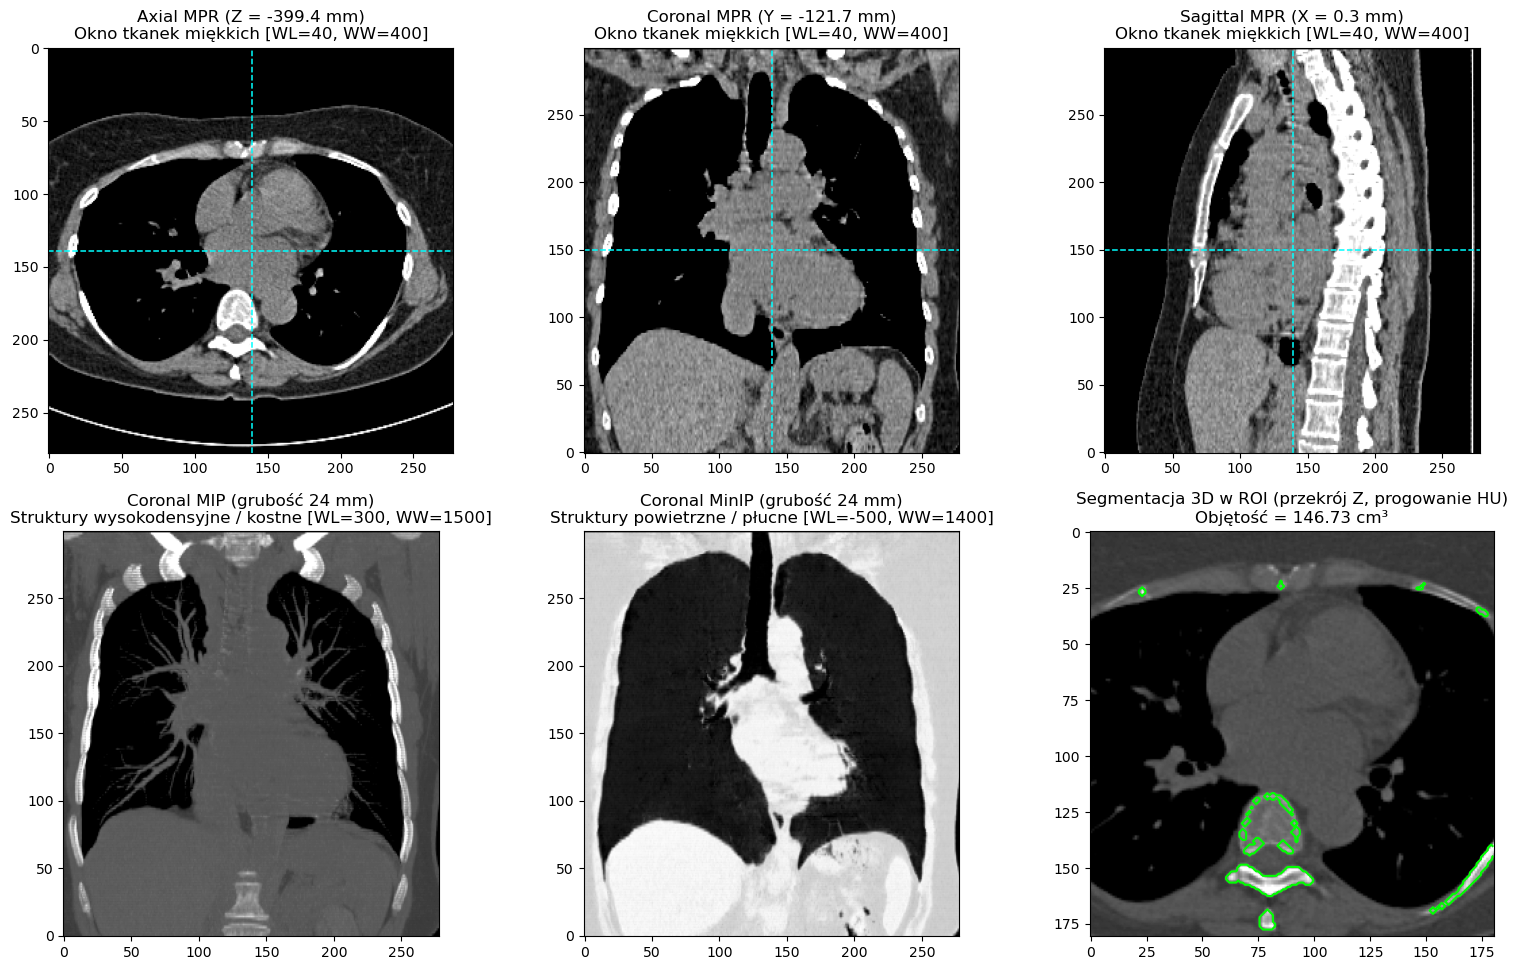

Zestawienie wolumetryczne przedziałów HU w badanym obszarze ROI 3D:


,Komponent tkankowy (przedział HU),Objętość [cm3],Średnia gęstość [HU],Odchylenie std [HU]
0,Struktury kostne / zwapnienia (250 do 3000 HU),146.73,585.52,271.17
1,Tkanki miękkie / miąższ (20 do 80 HU),991.90,46.11,15.41
2,Tkanka tłuszczowa (-150 do -30 HU),821.82,-106.81,26.60
3,Powietrze / miąższ płucny (-950 do -400 HU),1956.03,-830.80,98.92


In [11]:
# =========================================================
# WYKONANIE ANALIZY 3D I WIZUALIZACJA MPR / MIP / MinIP / ROI
# =========================================================
vol_iso = resample_to_isotropic(vol_3d, new_spacing=(1.0, 1.0, 1.0))
print(f"Rozmiar wolumenu po resamplingu izotropowym (X, Y, Z): {vol_iso.GetSize()} wokseli")

# Punkt referencyjny w środku fizycznym wolumenu (możesz podać własne współrzędne w mm)
target_pt = get_volume_center_mm(vol_iso)
proj_dict = extract_mpr_and_projections(vol_iso, target_mm=target_pt, slab_thickness_mm=24.0)

# Wolumetria struktur kostnych / wysokodensyjnych [250, 3000] HU w centralnym ROI 3D
metrics, roi_sub, clean_mask = quantify_structure_3d(
    vol_iso,
    target_mm=target_pt,
    half_box_mm=(90.0, 90.0, 75.0),
    hu_range=(250.0, 3000.0),
)

df_metrics = pd.DataFrame.from_dict(metrics, orient="index", columns=["Wartość"])
display(df_metrics.round(2))

ix, iy, iz = proj_dict["indices"]
fig, ax = plt.subplots(2, 3, figsize=(16, 9.8))

# Wiersz 1: Trzy ortogonalne płaszczyzny MPR w oknie tkanek miękkich (WL=40, WW=400)
ax[0, 0].imshow(apply_ct_window(proj_dict["axial"], wl=40, ww=400), cmap="gray")
ax[0, 0].axvline(ix, color="cyan", linestyle="--", lw=1.1)
ax[0, 0].axhline(iy, color="cyan", linestyle="--", lw=1.1)
ax[0, 0].set_title(f"Axial MPR (Z = {target_pt[2]:.1f} mm)\nOkno tkanek miękkich [WL=40, WW=400]")

ax[0, 1].imshow(apply_ct_window(proj_dict["coronal"], wl=40, ww=400), cmap="gray", origin="lower")
ax[0, 1].axvline(ix, color="cyan", linestyle="--", lw=1.1)
ax[0, 1].axhline(iz, color="cyan", linestyle="--", lw=1.1)
ax[0, 1].set_title(f"Coronal MPR (Y = {target_pt[1]:.1f} mm)\nOkno tkanek miękkich [WL=40, WW=400]")

ax[0, 2].imshow(apply_ct_window(proj_dict["sagittal"], wl=40, ww=400), cmap="gray", origin="lower")
ax[0, 2].axvline(iy, color="cyan", linestyle="--", lw=1.1)
ax[0, 2].axhline(iz, color="cyan", linestyle="--", lw=1.1)
ax[0, 2].set_title(f"Sagittal MPR (X = {target_pt[0]:.1f} mm)\nOkno tkanek miękkich [WL=40, WW=400]")

# Wiersz 2: Coronal MIP, Coronal MinIP oraz przekrój centralny segmentacji 3D w ROI
ax[1, 0].imshow(apply_ct_window(proj_dict["coronal_mip"], wl=300, ww=1500), cmap="gray", origin="lower")
ax[1, 0].set_title("Coronal MIP (grubość 24 mm)\nStruktury wysokodensyjne / kostne [WL=300, WW=1500]")

ax[1, 1].imshow(apply_ct_window(proj_dict["coronal_minip"], wl=-500, ww=1400), cmap="gray", origin="lower")
ax[1, 1].set_title("Coronal MinIP (grubość 24 mm)\nStruktury powietrzne / płucne [WL=-500, WW=1400]")

mid_z_roi = roi_sub.shape[0] // 2
ax[1, 2].imshow(apply_ct_window(roi_sub[mid_z_roi, :, :], wl=300, ww=1500), cmap="gray")
if np.any(clean_mask[mid_z_roi, :, :]):
    ax[1, 2].contour(clean_mask[mid_z_roi, :, :], colors="lime", linewidths=1.5)
ax[1, 2].set_title(
    f"Segmentacja 3D w ROI (przekrój Z, progowanie HU)\n"
    f"Objętość = {metrics['Objętość wysegmentowanej struktury [cm3]']:.2f} cm³"
)

plt.tight_layout()
plt.show()

# Dodatkowe zestawienie wolumetryczne dla głównych przedziałów gęstości HU w tym samym ROI 3D
tissue_presets = [
    ("Struktury kostne / zwapnienia (250 do 3000 HU)", (250.0, 3000.0)),
    ("Tkanki miękkie / miąższ (20 do 80 HU)", (20.0, 80.0)),
    ("Tkanka tłuszczowa (-150 do -30 HU)", (-150.0, -30.0)),
    ("Powietrze / miąższ płucny (-950 do -400 HU)", (-950.0, -400.0)),
]

summary_rows = []
for label, hu_win in tissue_presets:
    m_t, _, _ = quantify_structure_3d(vol_iso, target_mm=target_pt, half_box_mm=(90.0, 90.0, 75.0), hu_range=hu_win)
    summary_rows.append({
        "Komponent tkankowy (przedział HU)": label,
        "Objętość [cm3]": m_t["Objętość wysegmentowanej struktury [cm3]"],
        "Średnia gęstość [HU]": m_t["Średnia gęstość radiologiczna [HU]"],
        "Odchylenie std [HU]": m_t["Odchylenie standardowe gęstości [HU]"],
    })

print("Zestawienie wolumetryczne przedziałów HU w badanym obszarze ROI 3D:")
display(pd.DataFrame(summary_rows).round(2))